> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage2_wiki_and_semantic_graph_en.ipynb`)](../en/stage2_wiki_and_semantic_graph_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../../methodology/ko/02_stage2_wiki_and_semantic_graph_ko.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage2)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → **[▶ Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb)** → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 2. [파싱 & 통합] 비정형 정책 가이드 파싱 · 3-Layer LLM-Wiki 컴파일 & 시맨틱 온톨로지 그래프
## Step 2.1 SHA-256 해시 앵커 청킹 및 OKF v0.2 3-Layer Wiki 생성 · Step 2.2 도메인 규칙 및 시맨틱 그래프 통합 (`Entity=Node`, `Concept=Edge`)

Stage 2는 방법론의 **Phase 3(파싱)**과 **Phase 4(통합)**를 구현합니다. `pipeline/ingest.py`의 `run_ingest()`가 원시 정책 가이드(`01_guides/*.md`)를 문단 단위(`DOC_CHUNK_001~005`)로 파싱하여 원문 변조 여부를 즉시 검증할 수 있는 **결정론적 SHA-256 해시 앵커(`anchor_<12hex>`)**를 부여하고, 이를 **Andrej Karpathy 3-Layer LLM-Wiki(`summary.md`, `entities.md`, `concepts.md`, `rules.md`)** 및 **시맨틱 온톨로지 그래프(`ontology.jsonld`, `tb_domain_rules`, `edge_rule_applies_to_plan`)**로 통합합니다.

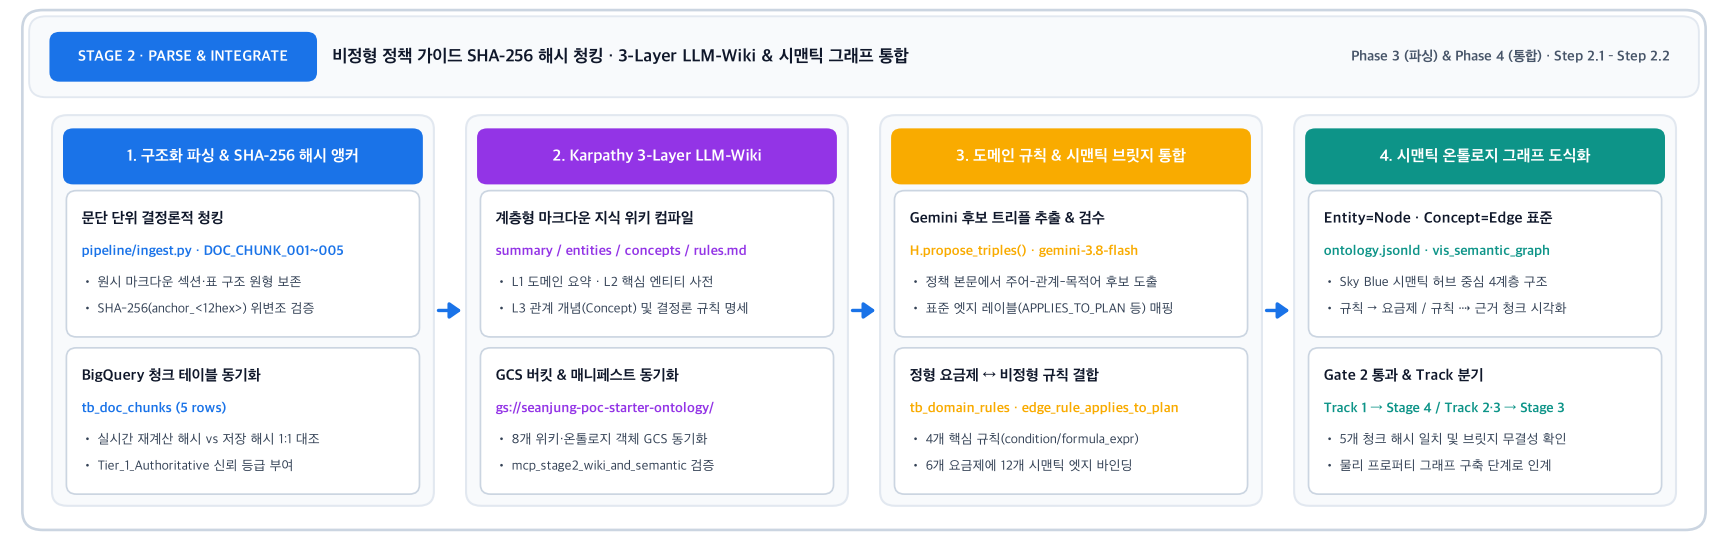


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("ko")
server = DomainMcpServer()


### 1. [Phase 3a: 파싱 (Parsing)] 원시 정책 마크다운(`01_guides/*.md`) 정규식 청크 분할 및 SHA-256 해시 앵커 무결성 대조 (`pipeline/ingest.py`)


In [2]:
df_parsed = H.parse_guides_live_demo()
H.show(df_parsed)


,chunk_id,source_file,section_title,chars,computed_anchor,bq_stored_anchor,sha256_match,excerpt
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,222,anchor_a52e1a72869f,anchor_a52e1a72869f,True,## 1. General Principles
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),467,anchor_3003b683cea0,anchor_3003b683cea0,True,## 2. 180-Day Baseline Plan Commitment Rule
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,444,anchor_47971ec8e4d8,anchor_47971ec8e4d8,True,## 3. Penalty Settlement Computation Formula
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,583,anchor_269d9c42e05c,anchor_269d9c42e05c,True,## 4. Statutory Penalty Exemption Clauses (위약금 면제 특례 규정)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,472,anchor_4fbaf9c5cba8,anchor_4fbaf9c5cba8,True,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPA


In [3]:
%%bqsql df_bq_chunks
SELECT chunk_id, source_file, section_title, trust_tier, content_sha256,
       CHAR_LENGTH(content) AS char_len, SUBSTR(content, 1, 85) AS content_preview
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks`
ORDER BY chunk_id


,chunk_id,source_file,section_title,trust_tier,content_sha256,char_len,content_preview
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,SYNTHETIC_DEMO,anchor_a52e1a72869f,222,## 1. General Principles\nThis document define...
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),SYNTHETIC_DEMO,anchor_3003b683cea0,467,## 2. 180-Day Baseline Plan Commitment Rule\n1...
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,SYNTHETIC_DEMO,anchor_47971ec8e4d8,444,## 3. Penalty Settlement Computation Formula\n...
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,SYNTHETIC_DEMO,anchor_269d9c42e05c,583,## 4. Statutory Penalty Exemption Clauses (위약금...
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,SYNTHETIC_DEMO,anchor_4fbaf9c5cba8,472,## 5. Public Subsidy vs. 25% Selective Contrac...


In [4]:
H.show(df_bq_chunks)


,chunk_id,source_file,section_title,trust_tier,content_sha256,char_len,content_preview
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,SYNTHETIC_DEMO,anchor_a52e1a72869f,222,"## 1. General Principles\nThis document defines standard commercial terms, device subs"
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),SYNTHETIC_DEMO,anchor_3003b683cea0,467,## 2. 180-Day Baseline Plan Commitment Rule\n1. Subscribers receiving public device su
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,SYNTHETIC_DEMO,anchor_47971ec8e4d8,444,## 3. Penalty Settlement Computation Formula\nThe subsidy difference penalty is calcul
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,SYNTHETIC_DEMO,anchor_269d9c42e05c,583,## 4. Statutory Penalty Exemption Clauses (위약금 면제 특례 규정)\n1. **Senior & Social Welfare
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,SYNTHETIC_DEMO,anchor_4fbaf9c5cba8,472,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPARE`)\n1. **


### 2. [Phase 3b: 위키 컴파일 & GCS 동기화] Andrej Karpathy 3-Layer LLM-Wiki (`summary.md`, `entities.md`, `concepts.md`, `rules.md`) 및 `mcp_stage2_wiki_and_semantic` 실행


In [5]:
df_wiki, manifest = H.wiki_compilation_summary()
H.md(f"**GCS Manifest Status**: `{manifest['status']}` · Bucket `{manifest['gcs_uri']}` · Uploaded Objects `{len(manifest['uploaded_gcs_objects'])}` · Loaded BQ Tables `{manifest['validation']['bigquery_tables_loaded']}`")
H.show(df_wiki)
for fname in ("summary.md", "entities.md", "concepts.md", "rules.md"):
    H.show_md_file(H.ROOT / "data/llm_wiki/ko" / fname, max_lines=22)
res_s2 = server.execute_tool("mcp_stage2_wiki_and_semantic", {"steps": ["compile_3layer_wiki", "extract_hash_anchors", "bind_semantic_bridges"]})
H.show_tool(res_s2, "anchored_chunks")


**GCS Manifest Status**: `LIVE_GCP_SYNCED` · Bucket `gs://seanjung-poc-starter-ontology/` · Uploaded Objects `8` · Loaded BQ Tables `10`

,wiki_layer,file,lines,gcs_object_uri,role
0,Layer 1 (Executive Summary),summary.md,8,gs://seanjung-poc-starter-ontology/ontology/summary.md,"Domain scope, OKF v0.2 framework, total chunks & BigQuery tables"
1,Layer 2 (Core Entities),entities.md,31,gs://seanjung-poc-starter-ontology/ontology/entities.md,"Compiled directory of contracts, devices, plans, and subsidy policies"
2,Layer 3 (Semantic Concepts),concepts.md,7,gs://seanjung-poc-starter-ontology/ontology/concepts.md,"Entity=Node, Concept=Edge relationship definitions (4 edge types)"
3,Layer 3 (Codified Rules),rules.md,22,gs://seanjung-poc-starter-ontology/ontology/rules.md,"Deterministic business rules with condition_expr, formula_expr & chunk anchors"


**`summary.md`** (8 lines)

#### Enterprise Knowledge Wiki: Executive Summary (Layer 1)
- **Domain**: Telecom Terminal Subsidy, Tariff Plans & Customer Commitment Management
- **Target Framework**: OKF v0.2 & Dual Property Graph (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)
- **Total Parsed Chunks**: 5 (Across 2 Policy Guides)
- **BigQuery Tables Loaded**: 10 tables in `seanjung-poc.starter_ontology_dw` (schema: `terraform/bigquery.tf`)

#### Operational Philosophy
Unstructured policy guides and structured BigQuery tables share one ontology. The agent answers with live BigQuery SQL/GQL results, SHA-256 paragraph anchors and Vertex AI Gemini, and cites the rule and chunk used.

**`entities.md`** (31 lines)

#### Enterprise Knowledge Wiki: Core Entities Directory (Layer 2)
Generated from `data/input/03_tables/*.csv` (the rows loaded into `seanjung-poc.starter_ontology_dw`).

#### 1. Customer Contract Ledger (`tb_customer_contract`)
- `CONTRACT_DEMO_101` (`CUST_DEMO_001` · General VIP · `DEV-S26U-256` · `PLAN-5G-85` · 120 Days Elapsed)
- `CONTRACT_DEMO_102` (`CUST_DEMO_002` · General Standard · `DEV-S26U-256` · `PLAN-5G-130` · 224 Days Elapsed)
- `CONTRACT_DEMO_103` (`CUST_DEMO_003` · Senior Welfare · `DEV-IP16P-256` · `PLAN-5G-85` · 88 Days Elapsed · `SENIOR_EXEMPT`)
- `CONTRACT_DEMO_104` (`CUST_DEMO_004` · General Standard · `DEV-S26U-512` · `PLAN-5G-85` · 109 Days Elapsed · `SELECTIVE_25PCT`)
- `CONTRACT_DEMO_105` (`CUST_DEMO_005` · Youth Family · `DEV-IP16P-512` · `PLAN-5G-61` · 57 Days Elapsed · `MILITARY_PAUSE_ELIGIBLE`)
- `CONTRACT_DEMO_106` (`CUST_DEMO_006` · Corporate B2B · `DEV-S26U-256` · `PLAN-5G-45` · 170 Days Elapsed)

#### 2. Terminal Device Master (`tb_device_master`)
- `Galaxy S26 Ultra 256GB` (`DEV-S26U-256`, Factory Price: 1,698,400 KRW)
- `Galaxy S26 Ultra 512GB` (`DEV-S26U-512`, Factory Price: 1,841,400 KRW)
- `iPhone 16 Pro 256GB` (`DEV-IP16P-256`, Factory Price: 1,700,000 KRW)
- `iPhone 16 Pro 512GB` (`DEV-IP16P-512`, Factory Price: 2,000,000 KRW)

#### 3. Tariff Plan Master (`tb_plan_master`)
- `5G Premier Super` (`PLAN-5G-130`, 130,000 KRW, Minimum Maintenance: 180 Days)
- `5G Premier Essential` (`PLAN-5G-85`, 85,000 KRW, Minimum Maintenance: 180 Days)
- `5G Direct 61` (`PLAN-5G-61`, 61,000 KRW, Minimum Maintenance: 180 Days)
- `5G Slim (Baseline Threshold)` (`PLAN-5G-45`, 45,000 KRW, Minimum Maintenance: 180 Days)

**`concepts.md`** (7 lines)

#### Enterprise Knowledge Wiki: Semantic Concepts & Edges (Layer 3)
In the Agentic Ontology Studio graph model, **Entities are represented as Nodes** and **Semantic Concepts/Relationships are represented as Edges**:

1. `USES_DEVICE` (`개통 단말기 관계`): Links a Customer Contract (`tb_customer_contract`) to its Terminal Device (`tb_device_master`).
2. `SUBSCRIBES_PLAN` (`가입 요금제 관계`): Links a Customer Contract (`tb_customer_contract`) to its Tariff Plan (`tb_plan_master`).
3. `HAS_SUBSIDY_POLICY` (`단말×요금제 지원금 결합`): Connects a Terminal Device (`tb_device_master`) to a Tariff Plan (`tb_plan_master`) with public and distribution subsidy amounts.
4. `APPLIES_TO_PLAN` (`비즈니스 규칙 적용`): Binds a codified Domain Rule (`tb_domain_rules`) to Tariff Plans (`tb_plan_master`) with SHA-256 chunk grounding.

**`rules.md`** (22 lines)

#### Enterprise Knowledge Wiki: Codified Business Rules (Layer 3)
Generated from `data/input/03_tables/domain_rules.csv` (BigQuery `tb_domain_rules`).

#### `RULE_SUBSIDY_CAP` · 공시지원금 및 유통망 추가지원금(15%) 합산 규칙 (`DOC_CHUNK_001`)
- **Condition**: `contract_type == 'PUBLIC_SUBSIDY'`
- **Formula**: `total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory_price_krw - total_subsidy`
- 유통망 추가지원금은 공시지원금의 최대 15%까지 지급되며, 실구매 원금은 출고가에서 총 지원금을 차감하여 산정함.

#### `RULE_SIX_PLAN_180D` · 180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙 (`DOC_CHUNK_003`)
- **Condition**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
- **Formula**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
- 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율((180-유지일수)/180)을 곱한 일할 위약금이 부과됨. 180일 경과 시 위약금 0원.

#### `RULE_WELFARE_EXEMPT` · 시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례 (`DOC_CHUNK_004`)
- **Condition**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
- **Formula**: `penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)`
- 만 65세 이상 시니어 복지 특례(SENIOR_EXEMPT) 대상자가 시니어/복지 요금제로 전환 시 180일 이내라도 차액정산 위약금을 100% 면제(0원)함.

#### `RULE_TCO_24M` · 24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙 (`DOC_CHUNK_005`)
- **Condition**: `commitment_months == 24`
- **Formula**: `subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); selective_24m_tco = factory_price_krw + (monthly_fee_krw * 0.75 * 24)`
- 24개월 총소유비용(TCO) 비교 시 공시지원금 총액과 24개월 25% 요금할인 총액(월정액×0.25×24)을 비교하여 유리한 약정을 추천함.

**`mcp_stage2_wiki_and_semantic`** · engine `bigquery` · status `SUCCESS` · steps `compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges` · jobs 1 (562.0 ms)

GCS 객체 24개 · 청크/규칙 조인 5행 (bigquery)

- `job_kWT5QcV0Ud4A6NvOh2pBjAdRWEzt`

,chunk_id,source_file,section_title,anchor,trust_tier,rule_id,rule_name,formula_expr
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,anchor_a52e1a72869f,SYNTHETIC_DEMO,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,SYNTHETIC_DEMO,NaN,NaN,NaN
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,anchor_47971ec8e4d8,SYNTHETIC_DEMO,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,anchor_269d9c42e05c,SYNTHETIC_DEMO,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,SYNTHETIC_DEMO,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...


### 3. [Phase 4a: 시맨틱 통합 (Integration)] Vertex AI Gemini(`gemini-3.8-flash`) 기반 후보 트리플 추출 및 도메인 규칙 ↔ 요금제 시맨틱 브릿지 테이블 확인 (`%%bqsql`)


In [6]:
triples = H.propose_triples(["DOC_CHUNK_001", "DOC_CHUNK_003", "DOC_CHUNK_004"])
H.show(triples)


BigQuery job `job_0m3Ga9-rZxeR-KKsF845cdOtW8IW` · Gemini `gemini-3.8-flash` · 토큰 2,112 · 30,441 ms · 6 개 후보

,subject,relation,object,chunk_id,existing_edge_label
0,consumer subscriptions,HAS_SUBSIDY_POLICY,device subsidy allocations,DOC_CHUNK_001,True
1,Statutory Exemption,APPLIES_TO_PLAN,"Senior, Youth, or Social Welfare plans",DOC_CHUNK_003,True
2,RULE_WELFARE_EXEMPT,APPLIES_TO_PLAN,designated Senior/Welfare tariff plans,DOC_CHUNK_004,True
3,Senior subscribers,EXEMPT_FROM,difference settlement penalties,DOC_CHUNK_004,False
4,Social Welfare subscribers,EXEMPT_FROM,difference settlement penalties,DOC_CHUNK_004,False
5,Active-duty enlistment,PAUSES,180-day mandatory commitment clock,DOC_CHUNK_004,False


In [7]:
%%bqsql df_rules
SELECT r.rule_id,
       r.rule_name AS rule_name,
       r.rule_category, r.condition_expr, r.formula_expr,
       r.source_chunk_id, c.section_title, c.content_sha256
FROM `seanjung-poc.starter_ontology_dw.tb_domain_rules` r
JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` c ON c.chunk_id = r.source_chunk_id
ORDER BY r.rule_id


,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,section_title,content_sha256
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee...,penalty = ROUND((initial_base_subsidy - lower_...,DOC_CHUNK_003,Penalty Math Formula,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_...,DOC_CHUNK_001,Overview & Scope,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_s...,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_...",penalty = 0 (SENIOR_EXEMPT) OR pause_commitmen...,DOC_CHUNK_004,Statutory Penalty Exemptions,anchor_269d9c42e05c


In [8]:
%%bqsql df_rule_plan
SELECT e.edge_id, e.rule_id, e.plan_id, p.plan_name, p.monthly_fee_krw,
       e.relation_label_ko AS relation_label_ko,
       e.source_chunk_id
FROM `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY e.rule_id, p.monthly_fee_krw DESC


,edge_id,rule_id,plan_id,plan_name,monthly_fee_krw,relation_label_ko,source_chunk_id
0,EDGE_RP_01,RULE_SIX_PLAN_180D,PLAN-5G-130,5G Premier Super,130000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
1,EDGE_RP_03,RULE_SIX_PLAN_180D,PLAN-5G-85,5G Premier Essential,85000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
2,EDGE_RP_05,RULE_SIX_PLAN_180D,PLAN-5G-61,5G Direct 61,61000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
3,EDGE_RP_07,RULE_SIX_PLAN_180D,PLAN-5G-45,5G Slim (Baseline Threshold),45000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
4,EDGE_RP_09,RULE_SIX_PLAN_180D,PLAN-5G-37,5G Light (Below Baseline),37000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
5,EDGE_RP_11,RULE_SIX_PLAN_180D,PLAN-LTE-33,LTE Basic (Below Baseline),33000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
6,EDGE_RP_02,RULE_TCO_24M,PLAN-5G-130,5G Premier Super,130000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
7,EDGE_RP_04,RULE_TCO_24M,PLAN-5G-85,5G Premier Essential,85000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
8,EDGE_RP_06,RULE_TCO_24M,PLAN-5G-61,5G Direct 61,61000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
9,EDGE_RP_08,RULE_TCO_24M,PLAN-5G-45,5G Slim (Baseline Threshold),45000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005


In [9]:
H.show(df_rules)
H.show(df_rule_plan)


,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,section_title,content_sha256
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,Penalty Math Formula,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,Overview & Scope,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,Statutory Penalty Exemptions,anchor_269d9c42e05c


,edge_id,rule_id,plan_id,plan_name,monthly_fee_krw,relation_label_ko,source_chunk_id
0,EDGE_RP_01,RULE_SIX_PLAN_180D,PLAN-5G-130,5G Premier Super,130000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
1,EDGE_RP_03,RULE_SIX_PLAN_180D,PLAN-5G-85,5G Premier Essential,85000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
2,EDGE_RP_05,RULE_SIX_PLAN_180D,PLAN-5G-61,5G Direct 61,61000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
3,EDGE_RP_07,RULE_SIX_PLAN_180D,PLAN-5G-45,5G Slim (Baseline Threshold),45000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
4,EDGE_RP_09,RULE_SIX_PLAN_180D,PLAN-5G-37,5G Light (Below Baseline),37000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
5,EDGE_RP_11,RULE_SIX_PLAN_180D,PLAN-LTE-33,LTE Basic (Below Baseline),33000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
6,EDGE_RP_02,RULE_TCO_24M,PLAN-5G-130,5G Premier Super,130000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
7,EDGE_RP_04,RULE_TCO_24M,PLAN-5G-85,5G Premier Essential,85000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
8,EDGE_RP_06,RULE_TCO_24M,PLAN-5G-61,5G Direct 61,61000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
9,EDGE_RP_08,RULE_TCO_24M,PLAN-5G-45,5G Slim (Baseline Threshold),45000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005


### 4. [Phase 4b: 시맨틱 그래프 설계 및 도식화] OKF v0.2 `ontology.jsonld` 명세 및 시맨틱 온톨로지 그래프 (`Entity=Node`, `Concept=Edge`)


,@id,@type,label,summary,totalChunks,supportedTracks,supportedGraphEngines,title,sourceDoc,hashAnchor
0,domain:TelecomSubsidyManagement,DomainOntology,Enterprise Subsidy & Contract Management (Starter v2.0),Hybrid ontology unifying structured BigQuery DW tables and unstructured policy manuals.,5.0,"[lite, standard, full]","[bigquery, spanner]",NaN,NaN,NaN
1,chunk:DOC_CHUNK_001,DocChunk,NaN,NaN,NaN,NaN,NaN,Overview & Scope,sample_policy_guide.md,anchor_a52e1a72869f
2,chunk:DOC_CHUNK_002,DocChunk,NaN,NaN,NaN,NaN,NaN,Baseline Plan Commitment (Six-Plan Rule),sample_policy_guide.md,anchor_3003b683cea0
3,chunk:DOC_CHUNK_003,DocChunk,NaN,NaN,NaN,NaN,NaN,Penalty Math Formula,sample_policy_guide.md,anchor_47971ec8e4d8
4,chunk:DOC_CHUNK_004,DocChunk,NaN,NaN,NaN,NaN,NaN,Statutory Penalty Exemptions,sample_welfare_exemption_guide.md,anchor_269d9c42e05c
5,chunk:DOC_CHUNK_005,DocChunk,NaN,NaN,NaN,NaN,NaN,24-Month Contract TCO Comparison Rule,sample_welfare_exemption_guide.md,anchor_4fbaf9c5cba8


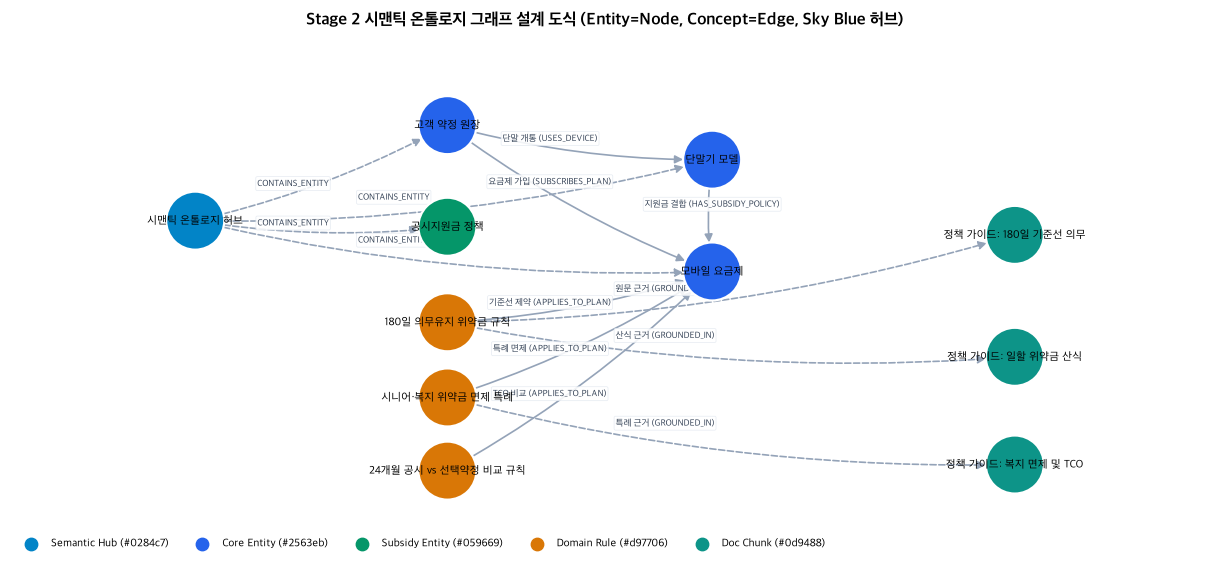

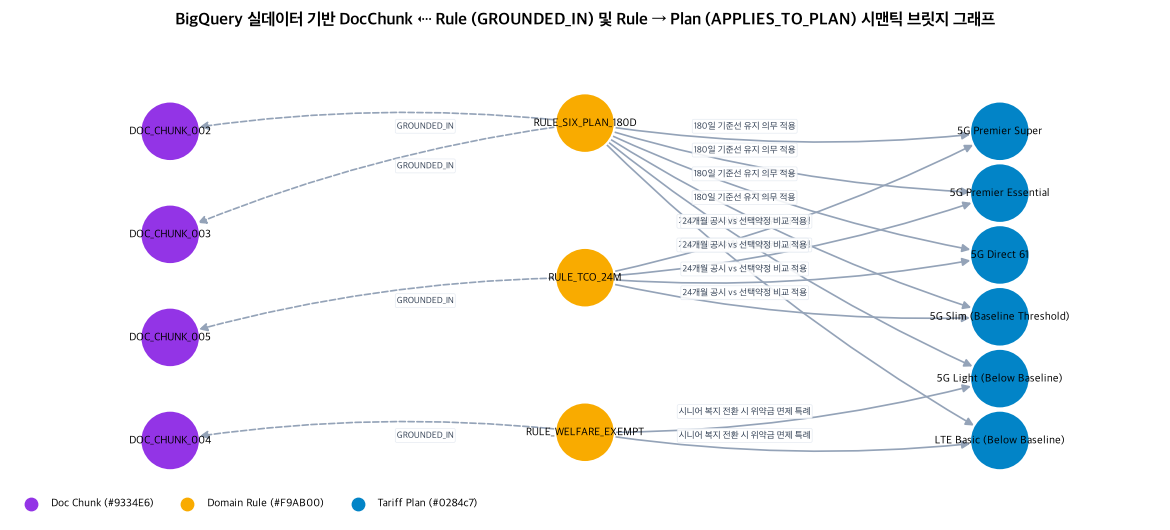

In [10]:
ont = H.read_json("data/output/ontology.jsonld")
H.show(pd.DataFrame(ont.get("@graph", [])))
H.draw_semantic_design_graph()

rp = H.pdf(df_rule_plan)
nodes, edges = [], []
for r in rp.itertuples():
    nodes.append({"id": r.source_chunk_id, "name": r.source_chunk_id, "color": "#9334E6", "layer": 0})
    nodes.append({"id": r.rule_id, "name": r.rule_id, "color": "#F9AB00", "layer": 1})
    nodes.append({"id": r.plan_name, "name": r.plan_name, "color": "#0284c7", "layer": 2})
    e_lbl = r.relation_label_ko if H.LANG == "ko" else "APPLIES_TO_PLAN"
    edges.append({"src": r.rule_id, "dst": r.plan_name, "label": e_lbl})
    edges.append({"src": r.rule_id, "dst": r.source_chunk_id, "label": "GROUNDED_IN", "style": "dashed"})
uniq_nodes = list({n["id"]: n for n in nodes}.values())
H.draw_graph(uniq_nodes, edges,
             "BigQuery 실데이터 기반 DocChunk ⇠ Rule (GROUNDED_IN) 및 Rule → Plan (APPLIES_TO_PLAN) 시맨틱 브릿지 그래프",
             layout="layers", figsize=(11.8, 5.4), node_size=1850,
             legend={"Doc Chunk (#9334E6)": "#9334E6", "Domain Rule (#F9AB00)": "#F9AB00", "Tariff Plan (#0284c7)": "#0284c7"})


### 5. [온톨로지 자기완결성 점검] 엔티티·개념 문서가 원문 근거를 스스로 담고 있는가

**권장 방법**
- 온톨로지 레이어의 엔티티·개념 문서마다 원문에서 요약한 핵심 사실을 원문 값, 문단 앵커, 짧은 인용과 함께 담는다. 원문에 없는 값은 쓰지 않는다.
- 그래프 설계와 그래프 데이터 적재는 온톨로지 폴더만으로 동작한다(frontmatter 기반 로더, 하드코딩 INSERT 없음).
- 검색은 온톨로지 문서를 먼저 보고, 부족하면 파싱 청크로 보완한다.
- 자산 레지스트리는 고객이 제공한 입력 문서만 관리한다(자동 수집한 규칙·용어 항목은 넣지 않는다).
- 승격 전 재추출 게이트 스크립트가 앵커·값·커버리지를 검사한다. `latest` 승격은 별도 단계이며 사람 검토 기록을 남긴다.

**스타터의 현재 구조 (권장 방법과 다름)**
- 위키는 집계 파일 4종(`summary.md`, `entities.md`, `concepts.md`, `rules.md`)과 `ontology.jsonld`이며, 엔티티별 개별 문서가 아니다. GCS 위치는 `gs://seanjung-poc-starter-ontology/ontology/`이다.
- `entities.md`는 CSV 테이블 행(`data/input/03_tables/*.csv`)에서 생성되고, `concepts.md`는 그래프 모델의 엣지 4종을 설명한다. 둘 다 문단 앵커가 없다. `rules.md`의 규칙은 `DOC_CHUNK` 앵커를 가진다.
- 물리 그래프는 온톨로지 폴더가 아니라 BigQuery 테이블 위에 선언된다(`pipeline/graph_builder.py`, Stage 3).
- 재추출 게이트와 `latest` 승격 단계는 없다. 가장 가까운 장치는 Lite 트랙의 `pipeline/extract_wiki.py`로, 인용문이 원문 청크에 그대로 있는 항목만 남긴다.

아래 셀은 로컬 위키 파일과 `ontology.jsonld`에서 항목 수와 청크 앵커(`DOC_CHUNK_*` 또는 `anchor_<12hex>`)를 가진 항목 수를 센다.


In [11]:
import re
wiki_dir = H.ROOT / "data/llm_wiki" / H.LANG
anchor_rows = []
for fname in ("entities.md", "concepts.md", "rules.md"):
    items = [ln for ln in (wiki_dir / fname).read_text(encoding="utf-8").splitlines() if re.match(r"^(- `|### `|\d+\. `)", ln)]
    anchor_rows.append({"file": f"data/llm_wiki/{H.LANG}/{fname}", "items": len(items),
                        "items_with_chunk_anchor": sum(bool(re.search(r"DOC_CHUNK_\d+|anchor_[0-9a-f]{12}", ln)) for ln in items)})
ont_chunks = [g for g in ont.get("@graph", []) if g.get("@type") == "DocChunk"]
anchor_rows.append({"file": "data/output/ontology.jsonld (DocChunk)", "items": len(ont_chunks),
                    "items_with_chunk_anchor": sum(bool(g.get("hashAnchor")) for g in ont_chunks)})
H.show(pd.DataFrame(anchor_rows))


,file,items,items_with_chunk_anchor
0,data/llm_wiki/ko/entities.md,21,0
1,data/llm_wiki/ko/concepts.md,4,0
2,data/llm_wiki/ko/rules.md,4,4
3,data/output/ontology.jsonld (DocChunk),5,5


### Q&A
- **Q.** 비정형 정책 가이드 문단과 정형 요금제 마스터 테이블은 어떻게 시맨틱하게 통합되나요?
  - **A.** `pipeline/ingest.py`가 정책 가이드를 `DOC_CHUNK_001~005`로 분할해 SHA-256 해시 앵커(`anchor_<12hex>`)를 부여하고, 문서 내 비즈니스 규칙을 `tb_domain_rules`(4건)로 코드화한 뒤 `edge_rule_applies_to_plan`(12건)을 통해 각 요금제(`plan_id`)와 근거 청크(`source_chunk_id`)를 양방향으로 바인딩합니다.

### Data Analysis Key Findings
- 원시 가이드 2종에서 파싱된 5개 청크(`DOC_CHUNK_001~005`)의 실시간 재계산 SHA-256 해시 앵커가 BigQuery `tb_doc_chunks.content_sha256`과 5건 모두 일치(`sha256_match=True`)합니다.
- 3-Layer LLM-Wiki(`summary.md`, `entities.md`, `concepts.md`, `rules.md`)와 `ontology.jsonld`를 포함해 총 8개 객체가 GCS(`gs://seanjung-poc-starter-ontology/`)와 동기화(`LIVE_GCP_SYNCED`)되었습니다.
- 4개 도메인 규칙(`RULE_SUBSIDY_CAP`, `RULE_SIX_PLAN_180D`, `RULE_WELFARE_EXEMPT`, `RULE_TCO_24M`)이 6개 요금제에 총 12개의 시맨틱 엣지(`APPLIES_TO_PLAN`)로 연결되어 시맨틱 그래프를 형성합니다.

### Insights or Next Steps
- Track 1(Lite) 환경은 이 단계 완료 후 바로 `Stage 4 (에이전트·답변)`로 이동할 수 있으며, Track 2/3 환경은 다음 `Stage 3 (그래프 구축)` 노트북으로 이동하여 Zero-ETL BigQuery/Spanner 물리 프로퍼티 그래프를 구축합니다.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [➡️ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [🌐 English Version](../en/stage2_wiki_and_semantic_graph_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/02_stage2_wiki_and_semantic_graph_ko.md)
